In [ ]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

import sys
sys.path.append("../..")

from src.backtester import calculate_return, backtester

Matplotlib is building the font cache; this may take a moment.


In [ ]:
df = pd.read_csv("../../data/spy_daily.csv")
prices = df["Adj Close"]
returns = calculate_return(prices)

#### Elementary Random Benchmark

In [ ]:
def generate_random_signal(prices, lookback):

    random_signal = [np.nan] * lookback

    choice = np.random.choice([0,1], size = len(prices) - lookback)

    random_signal = random_signal + choice.tolist()

    return random_signal

In [ ]:
df["Random Signal"] = generate_random_signal(prices, 252)
random_signal = df["Random Signal"]

In [ ]:
random_df, random_result = backtester(returns, random_signal, 0.001)
pd.Series(random_result)

In [21]:
def run_simulation(n):

    simulation_result = []

    for i in range(n):

        random_signal = generate_random_signal(prices, 252)
        _, random_result = backtester(returns, random_signal, 0.001)

        simulation_result.append(random_result)

    return simulation_result



In [39]:
np.random.seed(44)

simulation_output = run_simulation(100000)
simulation_df = pd.DataFrame(simulation_output)
simulation_df

,total_return,cagr,annual_volatility,annual_sharpe,max_drawdown,calmar,time_invested,trades
0,-0.900851,-0.086211,0.134085,-0.605255,-0.903483,-0.095421,0.493653,3279
1,-0.923670,-0.095487,0.130780,-0.701597,-0.931631,-0.102495,0.491486,3311
2,-0.940493,-0.104230,0.140298,-0.714127,-0.952875,-0.109384,0.491641,3253
3,-0.881654,-0.079880,0.139962,-0.524890,-0.900784,-0.088679,0.503715,3202
4,-0.817663,-0.064234,0.138258,-0.411022,-0.874031,-0.073492,0.503560,3206
...,...,...,...,...,...,...,...,...
99995,-0.889785,-0.082432,0.133564,-0.576929,-0.902229,-0.091364,0.503096,3292
99996,-0.766942,-0.055232,0.128464,-0.377908,-0.766942,-0.072016,0.499071,3186
99997,-0.909769,-0.089565,0.135962,-0.621966,-0.932437,-0.096054,0.499226,3121
99998,-0.801032,-0.061042,0.136836,-0.391641,-0.878102,-0.069516,0.510062,3211


#### Random Strategies Statistics

In [40]:
print(f"Sharpe Average: {simulation_df['annual_sharpe'].mean():.4f}")
print(f"Sharpe Median:  {simulation_df['annual_sharpe'].median():.4f}")
print(f"Largest Sharpe: {simulation_df['annual_sharpe'].max():.4f}")
print(f"Average No. of Trades: {simulation_df['trades'].mean():.4f}")
print(f"Average Time Invested: {simulation_df['time_invested'].mean():.4f}")

Sharpe Average: -0.5425
Sharpe Median:  -0.5422
Largest Sharpe: 0.0920
Average No. of Trades: 3229.8459
Average Time Invested: 0.5000


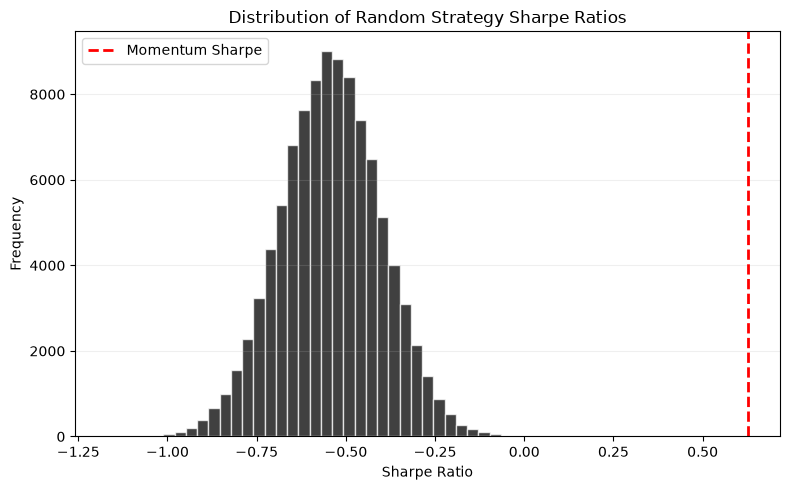

In [56]:
plt.figure(figsize=(8, 5))

plt.hist(
    simulation_df["annual_sharpe"],
    bins=40,
    color="black",
    alpha=0.75,
    edgecolor="white"
)

plt.axvline(
    0.627024,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Momentum Sharpe"
)

plt.xlabel("Sharpe Ratio")
plt.ylabel("Frequency")
plt.title("Distribution of Random Strategy Sharpe Ratios")

plt.legend()

plt.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()